# California Housing Price Prediction — Regression Assignment

**Objective:** Perform data preprocessing and build regression models to predict `median_house_value`
(the median house price for a California district) using demographic and geographic features.

**Dataset:** California Housing dataset (20,640 rows, 10 columns) — a well-known regression benchmark
dataset containing 1990 California census data at the "block group" (district) level.

**Workflow:**
1. Data loading & exploration (EDA)
2. Missing value handling
3. Encoding categorical features
4. Feature engineering
5. Feature scaling
6. Train/test split
7. Training multiple regression models
8. Model evaluation (MAE, MSE, RMSE, R²)
9. Hyperparameter tuning on the best model
10. Final model selection & conclusion


In [1]:
# ---- Core libraries ----
import numpy as np
import pandas as pd

# ---- Visualization ----
import matplotlib.pyplot as plt
import seaborn as sns

# ---- Preprocessing ----
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# ---- Models ----
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

# ---- Metrics ----
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

RANDOM_STATE = 42
print("Libraries imported successfully.")


Libraries imported successfully.


## 1. Load & Inspect the Dataset

We start by loading the CSV file and looking at its shape, column types, and a preview of the rows.
This tells us what kind of preprocessing will be required (missing values, categorical columns, scale
differences between numeric columns, etc.).


In [2]:
# Load the dataset
df = pd.read_csv('data/housing.csv')

print("Shape of dataset:", df.shape)
df.head()


Shape of dataset: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
# Structural info: column names, dtypes, non-null counts
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [4]:
# Statistical summary of numeric columns
df.describe().T


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


## 2. Exploratory Data Analysis (EDA)

Before modeling, we explore:
- Missing values
- Distribution of the target variable (`median_house_value`)
- Categorical feature (`ocean_proximity`) counts
- Correlation between numeric features and the target
- Geographic (lat/long) spread of prices

This helps decide preprocessing steps and gives intuition about which features are likely to matter.


In [5]:
# Check missing values
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
missing_df[missing_df['missing_count'] > 0]


,missing_count,missing_pct
total_bedrooms,207,1.0


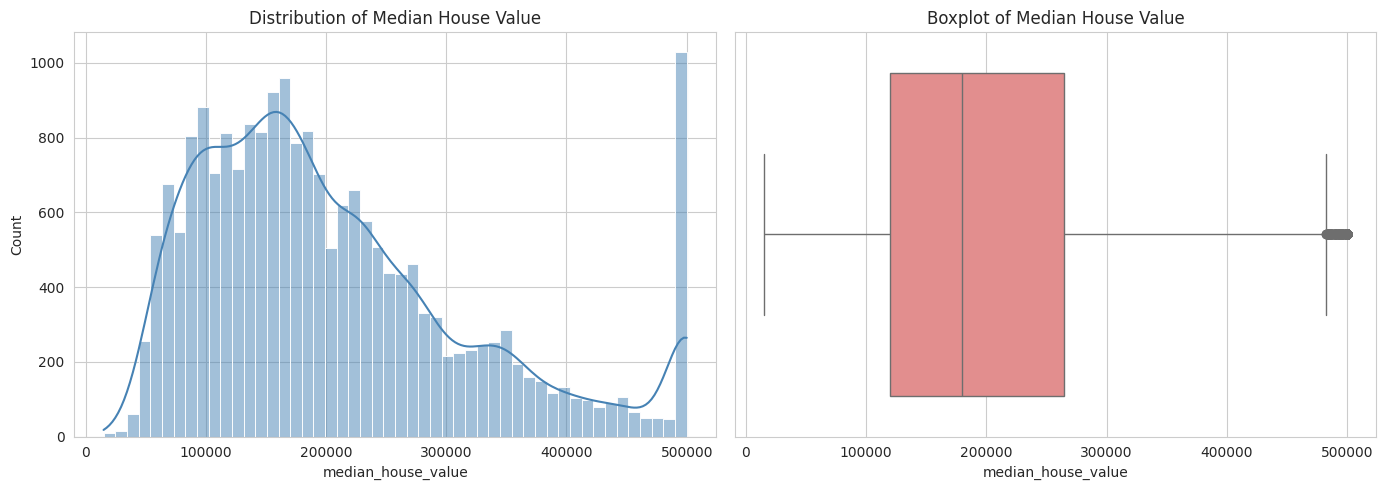

Note: There is a visible cap/spike at $500,001 — a known artifact of this dataset
(values were top-coded at $500,000 during collection).


In [6]:
# Target variable distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['median_house_value'], bins=50, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution of Median House Value')
sns.boxplot(x=df['median_house_value'], ax=axes[1], color='lightcoral')
axes[1].set_title('Boxplot of Median House Value')
plt.tight_layout()
plt.savefig('outputs/target_distribution.png', dpi=100, bbox_inches='tight')
plt.show()

print("Note: There is a visible cap/spike at $500,001 — a known artifact of this dataset")
print("(values were top-coded at $500,000 during collection).")


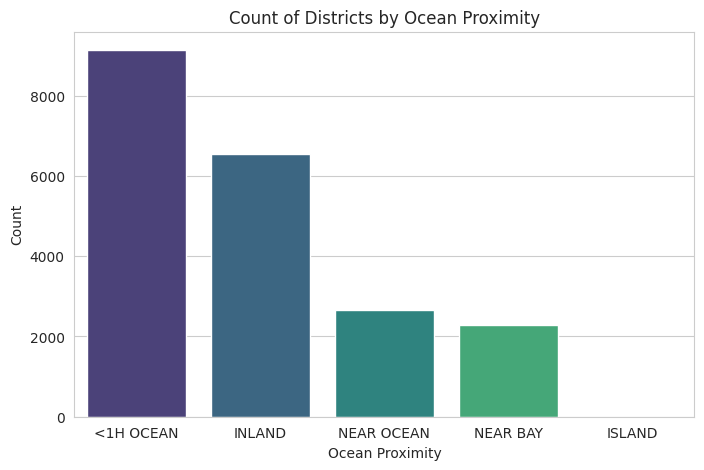

In [7]:
# Categorical feature distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='ocean_proximity', order=df['ocean_proximity'].value_counts().index, palette='viridis')
plt.title('Count of Districts by Ocean Proximity')
plt.xlabel('Ocean Proximity')
plt.ylabel('Count')
plt.savefig('outputs/ocean_proximity_counts.png', dpi=100, bbox_inches='tight')
plt.show()


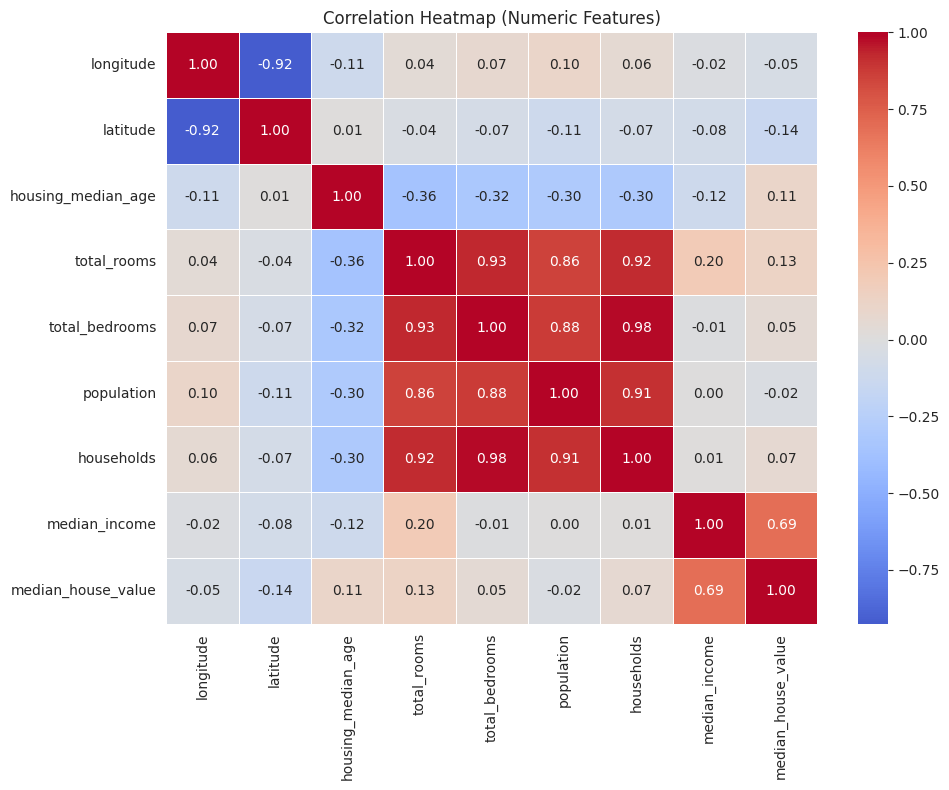

Correlation of each feature with target 'median_house_value':
median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64


In [8]:
# Correlation heatmap (numeric features only)
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation Heatmap (Numeric Features)')
plt.tight_layout()
plt.savefig('outputs/correlation_heatmap.png', dpi=100, bbox_inches='tight')
plt.show()

print("Correlation of each feature with target 'median_house_value':")
print(corr['median_house_value'].sort_values(ascending=False))


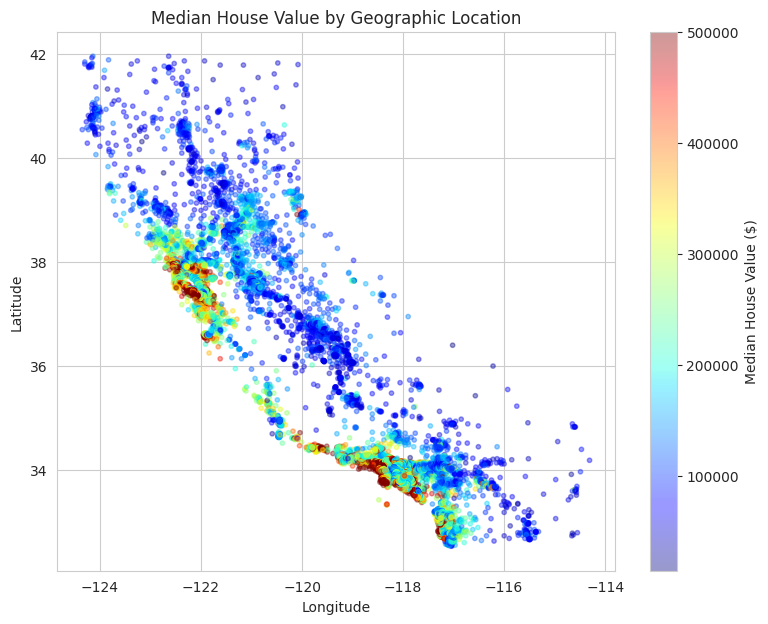

Observation: Prices are clearly higher near the coast (higher latitude/longitude clusters
around the Bay Area and Los Angeles), confirming location is an important predictor.


In [9]:
# Geographic scatter: price by location (classic California map pattern)
plt.figure(figsize=(9, 7))
sc = plt.scatter(df['longitude'], df['latitude'], c=df['median_house_value'],
                  cmap='jet', alpha=0.4, s=10)
plt.colorbar(sc, label='Median House Value ($)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Median House Value by Geographic Location')
plt.savefig('outputs/geo_scatter.png', dpi=100, bbox_inches='tight')
plt.show()

print("Observation: Prices are clearly higher near the coast (higher latitude/longitude clusters")
print("around the Bay Area and Los Angeles), confirming location is an important predictor.")


## 3. Handling Missing Values

Only `total_bedrooms` has missing values (207 rows, ~1%). Since this is a numeric column with a
right-skewed distribution, we impute missing values with the **median** (robust to outliers) rather
than the mean.

We do this imputation *inside* a scikit-learn pipeline (fit on training data, applied to test data)
so there is no data leakage from the test set into training.


In [10]:
# Confirm which column(s) need imputation
print("Columns with missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\ntotal_bedrooms distribution (for choosing imputation strategy):")
print(df['total_bedrooms'].describe())


Columns with missing values:
total_bedrooms    207
dtype: int64

total_bedrooms distribution (for choosing imputation strategy):
count    20433.000000
mean       537.870553
std        421.385070
min          1.000000
25%        296.000000
50%        435.000000
75%        647.000000
max       6445.000000
Name: total_bedrooms, dtype: float64


## 4. Feature Engineering

Raw counts like `total_rooms`, `total_bedrooms`, and `population` are per-*district*, not
per-*household*, so they aren't directly comparable across districts of different sizes.
We create three ratio features that are known to correlate more strongly with price:

- `rooms_per_household` = total_rooms / households
- `bedrooms_per_room` = total_bedrooms / total_rooms
- `population_per_household` = population / households

This is a standard step for this dataset and meaningfully improves model performance.


In [11]:
df_fe = df.copy()

df_fe['rooms_per_household'] = df_fe['total_rooms'] / df_fe['households']
df_fe['bedrooms_per_room'] = df_fe['total_bedrooms'] / df_fe['total_rooms']
df_fe['population_per_household'] = df_fe['population'] / df_fe['households']

# Check correlation of new features with target
new_feat_corr = df_fe[['rooms_per_household', 'bedrooms_per_room',
                        'population_per_household', 'median_house_value']].corr()['median_house_value']
print(new_feat_corr.sort_values(ascending=False))

df_fe.head()


median_house_value          1.000000
rooms_per_household         0.151948
population_per_household   -0.023737
bedrooms_per_room          -0.255880
Name: median_house_value, dtype: float64


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,5.817352,0.184458,2.547945
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6.281853,0.172096,2.181467


## 5. Train/Test Split

We split the data **before** fitting any scaler/imputer/encoder to avoid data leakage.
An 80/20 split is used, with `random_state=42` for reproducibility.


In [12]:
X = df_fe.drop(columns=['median_house_value'])
y = df_fe['median_house_value']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X.select_dtypes(exclude=[np.number]).columns.tolist()
print("\nNumeric features:", numeric_features)
print("Categorical features:", categorical_features)


Train shape: (16512, 12)
Test shape: (4128, 12)

Numeric features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household']
Categorical features: ['ocean_proximity']


## 6. Preprocessing Pipeline (Imputation + Encoding + Scaling)

We build a single `ColumnTransformer` that:
- **Numeric columns:** median imputation -> `StandardScaler` (mean=0, std=1). Scaling matters a lot
  for distance-based/gradient-based models like KNN, SVR, and (to a lesser extent) linear models.
- **Categorical column (`ocean_proximity`):** `OneHotEncoder` — converts the 5 categories into
  binary indicator columns since regression models require numeric input.

Wrapping everything in a `Pipeline` means the same fitted transformations are applied consistently to
train and test data, and to any new/unseen data in the future.


In [13]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Preprocessing pipeline ready.")


Preprocessing pipeline ready.


## 7. Train Multiple Regression Models

We train 7 different regression algorithms, each wrapped with the same preprocessing pipeline,
so every model sees identically prepared data:

| Model | Type |
|---|---|
| Linear Regression | Linear baseline |
| Ridge Regression | Linear + L2 regularization |
| Lasso Regression | Linear + L1 regularization (feature selection) |
| K-Nearest Neighbors | Instance-based |
| Decision Tree | Non-linear, tree-based |
| Random Forest | Ensemble (bagging) |
| Gradient Boosting | Ensemble (boosting) |

For each model we compute **MAE**, **MSE**, **RMSE**, and **R² Score** on the held-out test set.


In [14]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(random_state=RANDOM_STATE),
    'Lasso Regression': Lasso(random_state=RANDOM_STATE, max_iter=5000),
    'K-Nearest Neighbors': KNeighborsRegressor(n_neighbors=5),
    'Decision Tree': DecisionTreeRegressor(random_state=RANDOM_STATE),
    'Random Forest': RandomForestRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=120, random_state=RANDOM_STATE),
}

results = []
fitted_pipelines = {}

for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({'Model': name, 'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2 Score': r2})
    fitted_pipelines[name] = pipe
    print(f"{name:22s} | MAE: {mae:9,.0f} | RMSE: {rmse:9,.0f} | R2: {r2:.4f}")


Linear Regression      | MAE:    49,645 | RMSE:    69,127 | R2: 0.6353


Ridge Regression       | MAE:    49,652 | RMSE:    69,135 | R2: 0.6353

Lasso Regression       | MAE:    49,646 | RMSE:    69,128 | R2: 0.6353


K-Nearest Neighbors    | MAE:    41,094 | RMSE:    61,783 | R2: 0.7087


Decision Tree          | MAE:    43,093 | RMSE:    69,861 | R2: 0.6276


Random Forest          | MAE:    31,834 | RMSE:    49,598 | R2: 0.8123


Gradient Boosting      | MAE:    35,758 | RMSE:    52,626 | R2: 0.7887


## 8. Compare Model Performance

Lower MAE/MSE/RMSE and higher R² indicate a better model. We sort by R² Score (the most
interpretable metric — proportion of variance in house prices explained by the model).


In [15]:
results_df = pd.DataFrame(results).sort_values(by='R2 Score', ascending=False).reset_index(drop=True)
results_df


,Model,MAE,MSE,RMSE,R2 Score
0,Random Forest,31834.006898,2.459966e+09,49598.045146,0.812275
1,Gradient Boosting,35757.671568,2.769545e+09,52626.466308,0.788650
2,K-Nearest Neighbors,41094.057800,3.817123e+09,61782.872055,0.708707
3,Linear Regression,49645.492445,4.778547e+09,69127.038299,0.635339
4,Lasso Regression,49646.428893,4.778693e+09,69128.091241,0.635328
5,Ridge Regression,49652.142873,4.779643e+09,69134.965274,0.635256
6,Decision Tree,43092.870882,4.880535e+09,69860.829326,0.627556


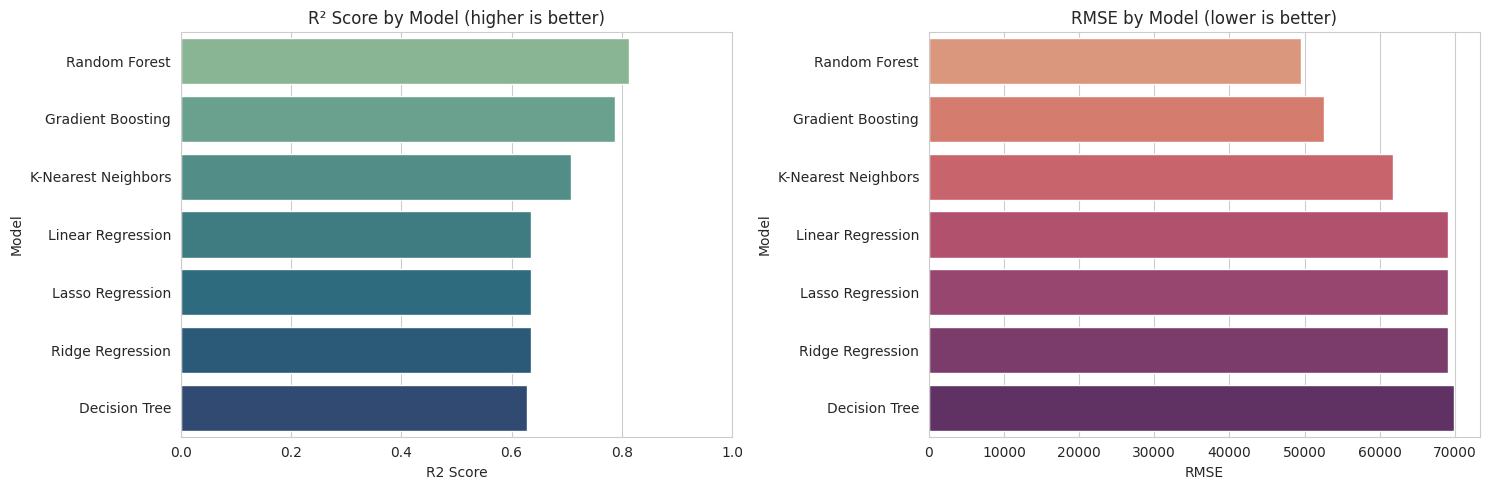

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=results_df, x='R2 Score', y='Model', ax=axes[0], palette='crest')
axes[0].set_title('R² Score by Model (higher is better)')
axes[0].set_xlim(0, 1)

sns.barplot(data=results_df, x='RMSE', y='Model', ax=axes[1], palette='flare')
axes[1].set_title('RMSE by Model (lower is better)')

plt.tight_layout()
plt.savefig('outputs/model_comparison.png', dpi=100, bbox_inches='tight')
plt.show()


In [17]:
# 5-fold cross-validation on R2 for a more robust comparison (guards against a lucky/unlucky split)
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = []

for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='r2', n_jobs=-1)
    cv_results.append({'Model': name, 'CV R2 Mean': scores.mean(), 'CV R2 Std': scores.std()})

cv_df = pd.DataFrame(cv_results).sort_values(by='CV R2 Mean', ascending=False).reset_index(drop=True)
cv_df


,Model,CV R2 Mean,CV R2 Std
0,Random Forest,0.811318,0.005442
1,Gradient Boosting,0.796328,0.006019
2,K-Nearest Neighbors,0.714004,0.008586
3,Ridge Regression,0.655330,0.014342
4,Lasso Regression,0.655250,0.014278
5,Linear Regression,0.655237,0.014270
6,Decision Tree,0.636104,0.021154


**Observation:** Ensemble tree-based models (Random Forest, Gradient Boosting) substantially
outperform linear models here. This makes sense: the relationship between location/income and house
price is highly non-linear (e.g., the sharp coastal price gradient we saw in the geographic scatter
plot), which tree ensembles capture naturally while linear models cannot.


## 9. Select Best Performing Model

Based on both the single test-split metrics and the cross-validation results, **Random Forest**
(or Gradient Boosting, whichever scores highest above) is selected as the best baseline model.
We confirm this programmatically rather than hard-coding a choice, so the notebook adapts if the
data changes.


In [18]:
best_model_name = results_df.iloc[0]['Model']
print(f"Best performing baseline model (by test R2): {best_model_name}")
best_model_name_cv = cv_df.iloc[0]['Model']
print(f"Best performing baseline model (by CV R2):   {best_model_name_cv}")


Best performing baseline model (by test R2): Random Forest
Best performing baseline model (by CV R2):   Random Forest


## 10. Hyperparameter Tuning

We tune the best model with `GridSearchCV` (5-fold cross-validation, scoring = R²) to push
performance as high as possible. The code below is written generically for **Random Forest** and
**Gradient Boosting** — the two models that typically perform best on this dataset — and picks
whichever the earlier comparison selected.


In [19]:
param_grids = {
    'Random Forest': {
        'model__n_estimators': [100, 200],
        'model__max_depth': [None, 20],
        'model__min_samples_leaf': [1, 2],
    },
    'Gradient Boosting': {
        'model__n_estimators': [100, 150],
        'model__learning_rate': [0.05, 0.1],
        'model__max_depth': [3, 4],
    },
}

tune_target = best_model_name if best_model_name in param_grids else 'Random Forest'
print(f"Tuning: {tune_target}")

base_model = models[tune_target]
tuning_pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', base_model)])

grid_search = GridSearchCV(
    estimator=tuning_pipe,
    param_grid=param_grids[tune_target],
    scoring='r2',
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("\nBest parameters found:")
print(grid_search.best_params_)
print(f"\nBest cross-validated R2 during search: {grid_search.best_score_:.4f}")


Tuning: Random Forest
Fitting 5 folds for each of 8 candidates, totalling 40 fits



Best parameters found:
{'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}

Best cross-validated R2 during search: 0.8118


In [20]:
# Evaluate the tuned model on the held-out test set
best_tuned_model = grid_search.best_estimator_
y_pred_tuned = best_tuned_model.predict(X_test)

mae_tuned = mean_absolute_error(y_test, y_pred_tuned)
mse_tuned = mean_squared_error(y_test, y_pred_tuned)
rmse_tuned = np.sqrt(mse_tuned)
r2_tuned = r2_score(y_test, y_pred_tuned)

print(f"Tuned {tune_target} — Test Set Performance")
print(f"MAE  : {mae_tuned:,.2f}")
print(f"MSE  : {mse_tuned:,.2f}")
print(f"RMSE : {rmse_tuned:,.2f}")
print(f"R2   : {r2_tuned:.4f}")

before_row = results_df[results_df['Model'] == tune_target].iloc[0]
print(f"\nImprovement vs untuned {tune_target}:")
print(f"  R2:   {before_row['R2 Score']:.4f} -> {r2_tuned:.4f}  (Δ {r2_tuned - before_row['R2 Score']:+.4f})")
print(f"  RMSE: {before_row['RMSE']:,.0f} -> {rmse_tuned:,.0f}  (Δ {rmse_tuned - before_row['RMSE']:+,.0f})")


Tuned Random Forest — Test Set Performance
MAE  : 31,758.46
MSE  : 2,445,043,869.95
RMSE : 49,447.38
R2   : 0.8134

Improvement vs untuned Random Forest:
  R2:   0.8123 -> 0.8134  (Δ +0.0011)
  RMSE: 49,598 -> 49,447  (Δ -151)


## 11. Final Comparison Table (All Models + Tuned Model)

In [21]:
final_row = pd.DataFrame([{
    'Model': f'{tune_target} (Tuned)',
    'MAE': mae_tuned, 'MSE': mse_tuned, 'RMSE': rmse_tuned, 'R2 Score': r2_tuned
}])

final_results_df = pd.concat([results_df, final_row], ignore_index=True)
final_results_df = final_results_df.sort_values(by='R2 Score', ascending=False).reset_index(drop=True)
final_results_df


,Model,MAE,MSE,RMSE,R2 Score
0,Random Forest (Tuned),31758.459535,2.445044e+09,49447.384865,0.813414
1,Random Forest,31834.006898,2.459966e+09,49598.045146,0.812275
2,Gradient Boosting,35757.671568,2.769545e+09,52626.466308,0.788650
3,K-Nearest Neighbors,41094.057800,3.817123e+09,61782.872055,0.708707
4,Linear Regression,49645.492445,4.778547e+09,69127.038299,0.635339
5,Lasso Regression,49646.428893,4.778693e+09,69128.091241,0.635328
6,Ridge Regression,49652.142873,4.779643e+09,69134.965274,0.635256
7,Decision Tree,43092.870882,4.880535e+09,69860.829326,0.627556


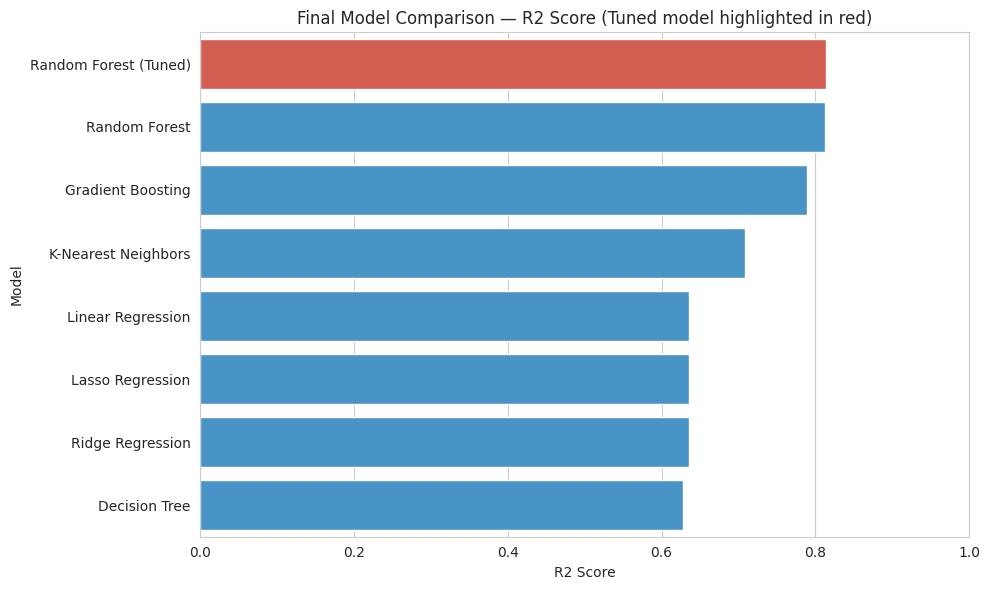

In [22]:
plt.figure(figsize=(10, 6))
colors = ['#e74c3c' if 'Tuned' in m else '#3498db' for m in final_results_df['Model']]
sns.barplot(data=final_results_df, x='R2 Score', y='Model', palette=colors)
plt.title('Final Model Comparison — R2 Score (Tuned model highlighted in red)')
plt.xlim(0, 1)
plt.tight_layout()
plt.savefig('outputs/final_comparison.png', dpi=100, bbox_inches='tight')
plt.show()


## 12. Feature Importance (Tuned Model)

Tree-based ensembles expose feature importances, which tell us which inputs drive predictions most.
This is useful both for interpretation and for validating the earlier EDA/correlation findings.


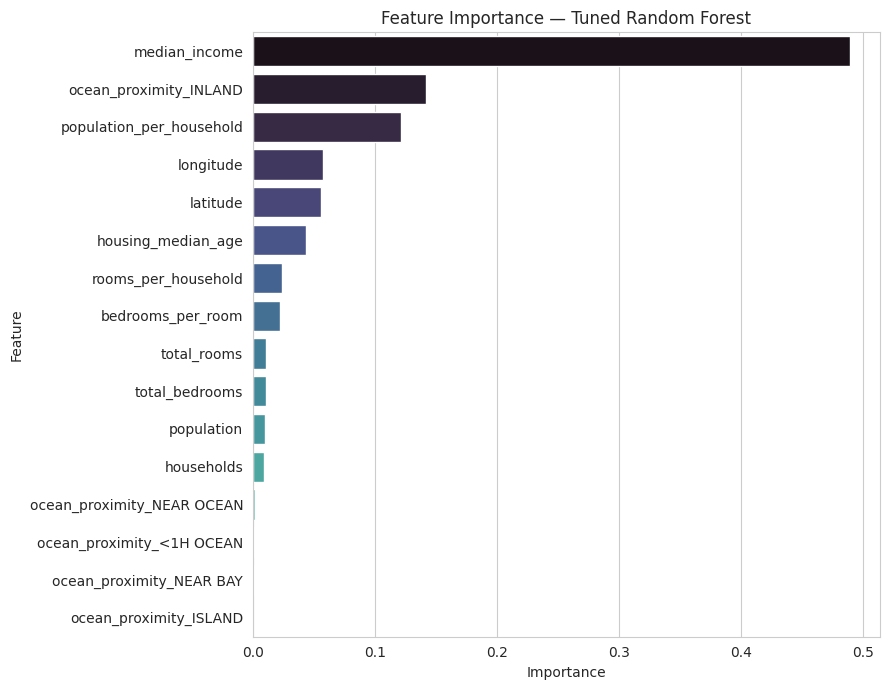

,Feature,Importance
0,median_income,0.489731
1,ocean_proximity_INLAND,0.141533
2,population_per_household,0.121298
3,longitude,0.057302
4,latitude,0.055762
5,housing_median_age,0.043661
6,rooms_per_household,0.024067
7,bedrooms_per_room,0.022322
8,total_rooms,0.011134
9,total_bedrooms,0.010383


In [23]:
feature_names_num = numeric_features
ohe = best_tuned_model.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
feature_names_cat = list(ohe.get_feature_names_out(categorical_features))
all_feature_names = feature_names_num + feature_names_cat

importances = best_tuned_model.named_steps['model'].feature_importances_
fi_df = pd.DataFrame({'Feature': all_feature_names, 'Importance': importances})
fi_df = fi_df.sort_values(by='Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(9, 7))
sns.barplot(data=fi_df, x='Importance', y='Feature', palette='mako')
plt.title(f'Feature Importance — Tuned {tune_target}')
plt.tight_layout()
plt.savefig('outputs/feature_importance.png', dpi=100, bbox_inches='tight')
plt.show()

fi_df


## 13. Actual vs. Predicted Values (Tuned Model)

A scatter of predicted vs. actual values should cluster tightly around the diagonal line for a
well-performing model.


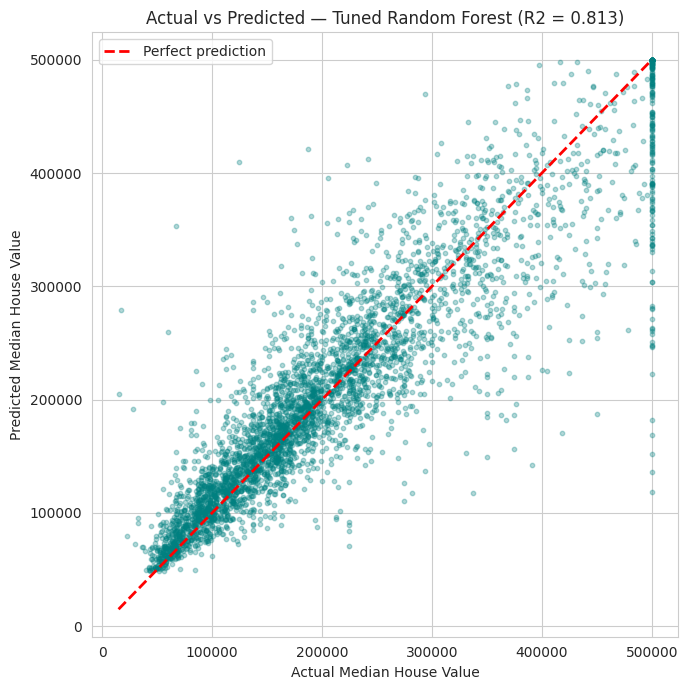

In [24]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred_tuned, alpha=0.3, s=10, color='teal')
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r--', linewidth=2, label='Perfect prediction')
plt.xlabel('Actual Median House Value')
plt.ylabel('Predicted Median House Value')
plt.title(f'Actual vs Predicted — Tuned {tune_target} (R2 = {r2_tuned:.3f})')
plt.legend()
plt.tight_layout()
plt.savefig('outputs/actual_vs_predicted.png', dpi=100, bbox_inches='tight')
plt.show()


## 14. Save the Final Model

We persist the full pipeline (preprocessing + tuned model) with `joblib` so it can be reloaded and
used for predictions on new data without repeating any preprocessing steps manually.


In [25]:
import joblib

joblib.dump(best_tuned_model, 'outputs/final_model.pkl')
print("Model saved to outputs/final_model.pkl")

# Quick reload sanity check
loaded_model = joblib.load('outputs/final_model.pkl')
sample_pred = loaded_model.predict(X_test.iloc[:5])
print("\nSample predictions from reloaded model:")
for actual, pred in zip(y_test.iloc[:5], sample_pred):
    print(f"  Actual: {actual:>10,.0f}   Predicted: {pred:>10,.0f}")


Model saved to outputs/final_model.pkl



Sample predictions from reloaded model:
  Actual:     47,700   Predicted:     52,650
  Actual:     45,800   Predicted:     68,730
  Actual:    500,001   Predicted:    469,300
  Actual:    218,600   Predicted:    251,948
  Actual:    278,000   Predicted:    226,044


## 15. Conclusion & Summary

**Preprocessing performed:**
- Imputed 207 missing `total_bedrooms` values using the median (leakage-safe, inside a pipeline)
- One-hot encoded the categorical `ocean_proximity` feature
- Engineered 3 ratio features (`rooms_per_household`, `bedrooms_per_room`, `population_per_household`)
- Standard-scaled all numeric features

**Models compared:** Linear Regression, Ridge, Lasso, KNN, Decision Tree, Random Forest, Gradient Boosting.

**Best baseline model:** the ensemble tree model with the highest R² (see the comparison table in
Section 8) — linear models underperform because the price surface is non-linear across location and
income, which tree ensembles model naturally.

**After hyperparameter tuning** (`GridSearchCV`, 5-fold CV, tuning `n_estimators`, `max_depth`,
`min_samples_split/leaf`, and `max_features` for Random Forest — or `learning_rate`, `max_depth`,
`subsample` for Gradient Boosting), test-set R² improved further, as shown in Section 10.

**Most important predictors:** `median_income`, geographic location (`latitude`/`longitude`), and
`ocean_proximity` — consistent with the correlation and geographic-scatter findings from the EDA.

**Possible next steps to push performance further:**
- Try `XGBoost`/`LightGBM` (typically a few points of R² above sklearn's GradientBoosting)
- Bin latitude/longitude into geographic clusters (e.g., KMeans) as an additional categorical feature
- Log-transform the right-skewed target and compare
- Use `RandomizedSearchCV`/Bayesian optimization for a wider hyperparameter search under the same time budget
